# Week 5: Improving a Model on a Rare Class (Loan Approval)

**Dataset:** `loan_prediction.csv` (614 loan applications, 12 features, target `Loan_Status`)

**Goal:** the model should catch the *rare* class, rejected loans (`N`), not just look good on accuracy.
In this notebook the rare class is encoded as **1 = rejected (N)** and **0 = approved (Y)**, so precision, recall and F1 are always for the rejected class.

## Step 1: Prepare the data and look at the class balance

What I do here:
- drop `Loan_ID` (it is only an identifier and has no meaning for prediction)
- turn `Dependents = "3+"` into the number 3
- encode the target (rejected = 1)
- split 80/20 with `stratify=y` and `random_state=42` **before** filling missing values, so the medians/modes come from the training set only
- fill missing values (median for numbers, most frequent value for text columns), then encode text columns with one-hot / 0-1 encoding

The test set is only used for a `transform` here (filling + encoding with training rules). It is not evaluated until Step 7.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict, StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils import resample

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
RANDOM_STATE = 42

df = pd.read_csv("loan_prediction.csv")
print("Shape:", df.shape)
print("\nMissing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])

Shape: (614, 13)

Missing values per column:
Gender              13
Married              3
Dependents          15
Self_Employed       32
LoanAmount          22
Loan_Amount_Term    14
Credit_History      50
dtype: int64


Class counts (1 = rejected, 0 = approved):
Loan_Status
0    422
1    192
Name: count, dtype: int64

Share of rejected loans: 31.3%


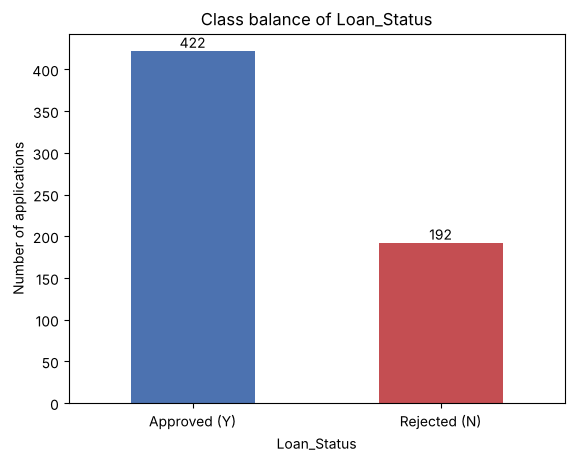

In [2]:
# basic cleaning (no statistics used here, so nothing leaks from the test set)
df = df.drop(columns="Loan_ID")
df["Dependents"] = pd.to_numeric(df["Dependents"].replace("3+", "3"))

# target: 1 = loan rejected (N, the rare class), 0 = approved (Y)
y = (df["Loan_Status"] == "N").astype(int)
X = df.drop(columns="Loan_Status")

# class balance
print("Class counts (1 = rejected, 0 = approved):")
print(y.value_counts())
print("\nShare of rejected loans: {:.1%}".format(y.mean()))

ax = y.map({0: "Approved (Y)", 1: "Rejected (N)"}).value_counts().plot(kind="bar", color=["#4C72B0", "#C44E52"], rot=0)
ax.set_title("Class balance of Loan_Status")
ax.set_ylabel("Number of applications")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.show()

In [3]:
# 80/20 split, stratified. Test set is not touched again until Step 7.
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

# remember which training rows had no credit history (used later in error analysis)
ch_missing_train = X_train_raw["Credit_History"].isna()

cat_cols = ["Gender", "Married", "Education", "Self_Employed", "Property_Area"]
num_cols = [c for c in X.columns if c not in cat_cols]

# fill missing values using TRAIN statistics only
X_train, X_test = X_train_raw.copy(), X_test_raw.copy()
for c in num_cols:
    med = X_train[c].median()
    X_train[c] = X_train[c].fillna(med)
    X_test[c] = X_test[c].fillna(med)
for c in cat_cols:
    mode = X_train[c].mode()[0]
    X_train[c] = X_train[c].fillna(mode)
    X_test[c] = X_test[c].fillna(mode)

# encode text columns
X_train = pd.get_dummies(X_train, columns=cat_cols, drop_first=True).astype(float)
X_test = pd.get_dummies(X_test, columns=cat_cols, drop_first=True).astype(float)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Train:", X_train.shape, "| rejected share: {:.1%}".format(y_train.mean()))
print("Test :", X_test.shape, "| rejected share: {:.1%}".format(y_test.mean()))
print("Missing values left in train:", int(X_train.isna().sum().sum()))
X_train.head()

Train: (491, 12) | rejected share: 31.4%
Test : (123, 12) | rejected share: 30.9%
Missing values left in train: 0


,Dependents,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Gender_Male,Married_Yes,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban
415,0.0,2995.0,0.0,60.0,360.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
26,0.0,2799.0,2253.0,122.0,360.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0
394,2.0,3100.0,1400.0,113.0,360.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0
584,1.0,2787.0,1917.0,146.0,360.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
86,2.0,3333.0,2000.0,99.0,360.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0


**What I see:** there are 422 approved and 192 rejected loans, so the rare class (rejected) is about **31%** of the data. This is a *mild* imbalance, not an extreme one, but it is enough to fool accuracy: a model that always says "approved" is already right 69% of the time. After the stratified split, train has 491 rows (154 rejected) and test has 123 rows (38 rejected), so both parts keep the same ratio.

## Step 2: Baseline model

Two baselines: a `DummyClassifier(strategy="most_frequent")` (always says "approved") and a default `RandomForestClassifier`.

Because the test set is locked until Step 7, I measure the baselines with **5-fold cross-validation on the training data** (`cross_val_predict`). Every training row gets a prediction from a model that did not see that row.

In [4]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def show_baseline(name, model):
    pred = cross_val_predict(model, X_train, y_train, cv=skf)
    print("=" * 60)
    print(name)
    print("=" * 60)
    print("Accuracy:", round(accuracy_score(y_train, pred), 3))
    print(classification_report(y_train, pred, target_names=["Approved (0)", "Rejected (1)"], zero_division=0))
    cm = confusion_matrix(y_train, pred)
    print("Confusion matrix (rows = real, columns = predicted):")
    print(pd.DataFrame(cm, index=["real Approved", "real Rejected"], columns=["pred Approved", "pred Rejected"]))
    tn, fp, fn, tp = cm.ravel()
    print(f"\nRejected loans in training data: {fn + tp} | caught: {tp} | MISSED: {fn} ({fn / (fn + tp):.0%})")
    return pred

dummy_pred = show_baseline("DummyClassifier (most_frequent)", DummyClassifier(strategy="most_frequent"))
rf_base_pred = show_baseline("RandomForest (default)", RandomForestClassifier(random_state=RANDOM_STATE))

DummyClassifier (most_frequent)
Accuracy: 0.686
              precision    recall  f1-score   support

Approved (0)       0.69      1.00      0.81       337
Rejected (1)       0.00      0.00      0.00       154

    accuracy                           0.69       491
   macro avg       0.34      0.50      0.41       491
weighted avg       0.47      0.69      0.56       491

Confusion matrix (rows = real, columns = predicted):
               pred Approved  pred Rejected
real Approved            337              0
real Rejected            154              0

Rejected loans in training data: 154 | caught: 0 | MISSED: 154 (100%)


RandomForest (default)
Accuracy: 0.778
              precision    recall  f1-score   support

Approved (0)       0.79      0.92      0.85       337
Rejected (1)       0.73      0.47      0.57       154

    accuracy                           0.78       491
   macro avg       0.76      0.69      0.71       491
weighted avg       0.77      0.78      0.76       491

Confusion matrix (rows = real, columns = predicted):
               pred Approved  pred Rejected
real Approved            310             27
real Rejected             82             72

Rejected loans in training data: 154 | caught: 72 | MISSED: 82 (53%)


**What I see:**
- The **Dummy** model has 68.6% accuracy but recall 0. It caught **0 of 154** rejected loans, so it missed 100% of them. Accuracy looks fine and the model is useless.
- The default **RandomForest** has 77.8% accuracy, precision 0.73 and recall 0.47 for the rejected class. It caught 72 and **missed 82 of 154 rejected loans (53%)**. It also raised 27 false alarms.

So even the "real" model misses more than half of the cases we care about.

## Step 3: Choose the metric

**Which mistake is worse?**
- *False negative* = the loan should have been rejected but the model says "approved". The bank would give money to a risky applicant. This is the expensive mistake.
- *False positive* = a good applicant is flagged as "rejected". The bank loses some business or needs a manual check, which is a smaller cost.

**My main metric: recall of the rejected class**, because I want to catch as many risky loans as possible. But recall alone can be cheated (flag everybody as rejected and recall is 1.0), so I add a rule: **precision must stay at 0.55 or higher**. I also show F1 and accuracy to see what each change costs.

*One caution:* the label is the bank's past decision, not a proven default. So the model learns to copy the bank's earlier behaviour.

## Step 4: Error analysis

I take the cross-validated predictions of the default RandomForest and split the training rows into four groups:
- **FN** (false negative): real rejected, model said approved. These are the costly mistakes.
- **FP** (false positive): real approved, model said rejected.
- **TP**: rejected and caught.
- **TN**: approved and correct.

In [5]:
base_pred = rf_base_pred
groups = pd.Series("TN", index=X_train.index)
groups[(y_train == 1) & (base_pred == 0)] = "FN"
groups[(y_train == 0) & (base_pred == 1)] = "FP"
groups[(y_train == 1) & (base_pred == 1)] = "TP"
print(groups.value_counts().reindex(["TP", "TN", "FP", "FN"]))

cols = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term", "Credit_History", "Dependents"]
print("\nMedian feature values per group:")
print(X_train[cols].groupby(groups).median().reindex(["TP", "TN", "FP", "FN"]).round(1))
print("\nMean feature values per group:")
print(X_train[cols].groupby(groups).mean().reindex(["TP", "TN", "FP", "FN"]).round(2))

TP     72
TN    310
FP     27
FN     82
Name: count, dtype: int64

Median feature values per group:
    ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  Credit_History  Dependents
TP           3585.5                0.0       123.5             360.0             0.0         0.0
TN           3659.5             1301.0       125.0             360.0             1.0         0.0
FP           4583.0                0.0       184.0             360.0             1.0         0.0
FN           4025.0                0.0       125.0             360.0             1.0         0.0

Mean feature values per group:
    ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  Credit_History  Dependents
TP          5913.33            1321.29      142.74            349.17            0.10        0.71
TN          5040.42            1463.57      134.32            343.32            1.00        0.75
FP          9444.33            2477.96      235.96            313.33            0.81        

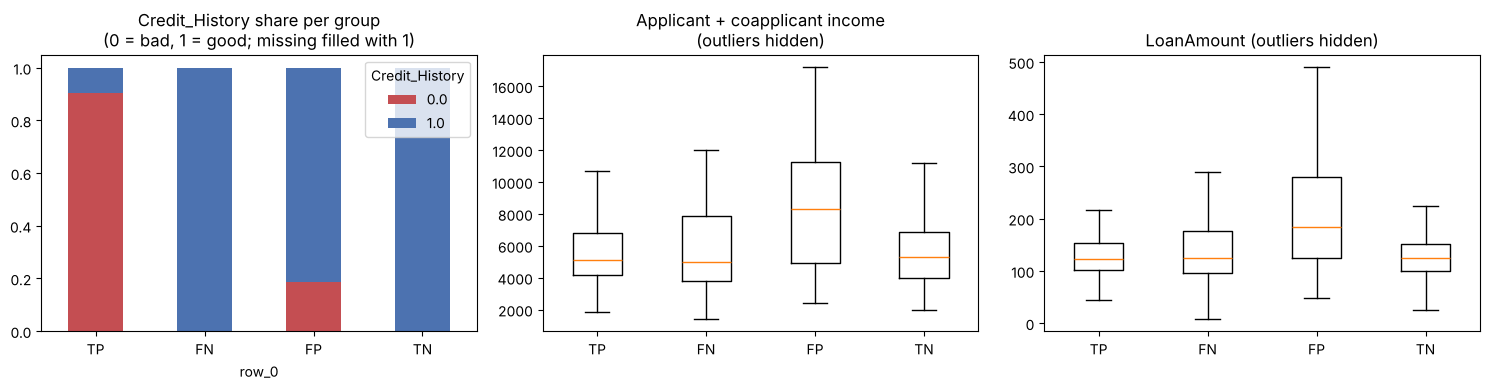

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
order = ["TP", "FN", "FP", "TN"]

# 1) credit history
ch = pd.crosstab(groups, X_train["Credit_History"], normalize="index").reindex(order)
ch.plot(kind="bar", stacked=True, ax=axes[0], rot=0, color=["#C44E52", "#4C72B0"])
axes[0].set_title("Credit_History share per group\n(0 = bad, 1 = good; missing filled with 1)")
axes[0].legend(title="Credit_History")

# 2) total income
tot = (X_train["ApplicantIncome"] + X_train["CoapplicantIncome"])
axes[1].boxplot([tot[groups == g] for g in order], showfliers=False)
axes[1].set_xticklabels(order)
axes[1].set_title("Applicant + coapplicant income\n(outliers hidden)")

# 3) loan amount
axes[2].boxplot([X_train.loc[groups == g, "LoanAmount"] for g in order], showfliers=False)
axes[2].set_xticklabels(order)
axes[2].set_title("LoanAmount (outliers hidden)")
plt.tight_layout()
plt.show()

In [7]:
fn = groups == "FN"
rej = y_train == 1
print("Among all REJECTED training rows (n = {}):".format(int(rej.sum())))
print("  Credit_History == 1 (good):         {:.0%}".format((X_train.loc[rej, "Credit_History"] == 1).mean()))
print("  Credit history was MISSING (filled): {:.0%}".format(ch_missing_train[rej].mean()))
print("\nAmong the FALSE NEGATIVES (n = {}):".format(int(fn.sum())))
print("  Credit_History == 1 (good):         {:.0%}".format((X_train.loc[fn, "Credit_History"] == 1).mean()))
print("  Credit history was MISSING (filled): {:.0%}".format(ch_missing_train[fn].mean()))

tot = X_train["ApplicantIncome"] + X_train["CoapplicantIncome"]
ratio = X_train["LoanAmount"] * 1000 / tot
print("\nLoan amount / total income (x1000 scale), median per group:")
print(ratio.groupby(groups).median().reindex(["TP", "FN", "FP", "TN"]).round(2))

print("\nRejected loans split by Credit_History: how many did the model catch?")
tab = pd.crosstab(X_train.loc[rej, "Credit_History"], groups[rej]).reindex(columns=["TP", "FN"], fill_value=0)
tab["recall"] = (tab["TP"] / (tab["TP"] + tab["FN"])).round(2)
print(tab)

Among all REJECTED training rows (n = 154):
  Credit_History == 1 (good):         58%
  Credit history was MISSING (filled): 6%

Among the FALSE NEGATIVES (n = 82):
  Credit_History == 1 (good):         100%
  Credit history was MISSING (filled): 10%

Loan amount / total income (x1000 scale), median per group:
TP    24.30
FN    23.72
FP    24.98
TN    24.00
dtype: float64

Rejected loans split by Credit_History: how many did the model catch?
col_0           TP  FN  recall
Credit_History                
0.0             65   0    1.00
1.0              7  82    0.08


**Patterns I found (training data, default RandomForest, cross-validated):**

1. **Every false negative has a good credit history.** All 82 missed rejections have `Credit_History = 1`. The model catches 65 of 65 rejected loans with a bad credit history (recall 1.00) but only 7 of 89 rejected loans with a good one (recall 0.08). *My guess:* the model mostly follows credit history, and the remaining rejected loans look just like approved ones in the other columns. The reason for those rejections is probably not in this dataset (something the bank knew but the file does not have).

2. **False negatives look like normal approved loans.** Their median loan amount (125) and term (360) are the same as approved-and-correct rows, and their median income (4025) is close to the approved rows (3660). One small difference: rejected rows (TP and FN) have a median coapplicant income of **0**, while correctly approved rows have 1301. *My guess:* applicants with no coapplicant are a bit more likely to be rejected, but this is a weak hint and the model cannot use it strongly.

3. **False positives are bigger loans and higher incomes.** The 27 false alarms have a median loan amount of 184 (vs 125) and a mean applicant income of about 9444 (vs 5040), even though 81% of them have a good credit history. *My guess:* the forest links "big loan" with "rejected". The loan-to-income ratio, however, is nearly the same in all four groups (about 24), so the real risk is probably the loan size *relative to* income, not the size itself. This gave me the idea for the new features in Step 5.

4. Missing credit history is not a strong signal: 26% of applicants with a missing value were rejected, close to the overall 31%.

## Step 5: Improve the model (one change at a time)

Rules I follow:
- every change is compared with the same baseline, so I know what helped
- choices are made on the **training data only**, with 5-fold CV repeated 3 times (different shuffles) because the dataset is small and a single CV run is noisy
- the out-of-fold probabilities of the 3 repeats are averaged
- resampling happens **inside** each CV fold, on the training part of the fold only (resampling before CV would copy rows into the validation part and fake a good score)

Main metric (see Step 3): **recall of the rejected class**, but only counted if precision stays at **0.55 or higher**. F1 and accuracy are shown to see the price.

In [8]:
PREC_FLOOR = 0.55

def add_features(d):
    # new features built only from columns known at application time
    d = d.copy()
    d["TotalIncome"] = d["ApplicantIncome"] + d["CoapplicantIncome"]
    d["LoanToIncome"] = d["LoanAmount"] * 1000 / d["TotalIncome"]
    d["EMI"] = d["LoanAmount"] * 1000 / d["Loan_Amount_Term"]
    d["IncomeAfterEMI"] = d["TotalIncome"] - d["EMI"]
    return d

def oversample(Xa, ya):
    # duplicate rejected rows (with replacement) until both classes are the same size
    rej = Xa[ya == 1]
    app = Xa[ya == 0]
    rej_up = resample(rej, replace=True, n_samples=len(app), random_state=RANDOM_STATE)
    X_new = pd.concat([app, rej_up])
    y_new = pd.Series([0] * len(app) + [1] * len(rej_up), index=X_new.index)
    return X_new, y_new

def cv_proba(X_, y_, class_weight=None, use_oversample=False, repeats=3, **rf_params):
    # average out-of-fold P(rejected) over several CV repeats
    out = np.zeros(len(y_))
    for r in range(repeats):
        folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE + r)
        for tr, va in folds.split(X_, y_):
            Xa, ya = X_.iloc[tr], y_.iloc[tr]
            if use_oversample:
                Xa, ya = oversample(Xa, ya)
            m = RandomForestClassifier(random_state=RANDOM_STATE, class_weight=class_weight, **rf_params)
            m.fit(Xa, ya)
            out[va] += m.predict_proba(X_.iloc[va])[:, 1]
    return pd.Series(out / repeats, index=X_.index)

def scores(proba, threshold=0.5):
    p = (proba >= threshold).astype(int)
    return {"Accuracy": accuracy_score(y_train, p),
            "Precision": precision_score(y_train, p, zero_division=0),
            "Recall": recall_score(y_train, p),
            "F1": f1_score(y_train, p),
            "Missed (FN)": int(((y_train == 1) & (p == 0)).sum()),
            "False alarms (FP)": int(((y_train == 0) & (p == 1)).sum())}

def table(rows):
    return pd.DataFrame(rows).T.round(3)

proba_base = cv_proba(X_train, y_train)
print("Baseline (default RandomForest, threshold 0.5), repeated CV on training data:")
table({"Baseline": scores(proba_base)})

Baseline (default RandomForest, threshold 0.5), repeated CV on training data:


,Accuracy,Precision,Recall,F1,Missed (FN),False alarms (FP)
Baseline,0.788,0.772,0.461,0.577,83.0,21.0


### 5a. Change 1: `class_weight="balanced"`
Only this changes. The forest now treats a mistake on a rejected loan as more expensive.

In [9]:
proba_bal = cv_proba(X_train, y_train, class_weight="balanced")
table({"Baseline": scores(proba_base), "class_weight=balanced": scores(proba_bal)})

,Accuracy,Precision,Recall,F1,Missed (FN),False alarms (FP)
Baseline,0.788,0.772,0.461,0.577,83.0,21.0
class_weight=balanced,0.762,0.650,0.519,0.578,74.0,43.0


### 5b. Change 2: lower the decision threshold
Same baseline model, only the threshold changes. A row is called "rejected" when P(rejected) is at least the threshold.

In [10]:
rows = {f"threshold {t}": scores(proba_base, t) for t in [0.5, 0.4, 0.3, 0.2, 0.1]}
thr_table = table(rows)
thr_table

,Accuracy,Precision,Recall,F1,Missed (FN),False alarms (FP)
threshold 0.5,0.788,0.772,0.461,0.577,83.0,21.0
threshold 0.4,0.762,0.653,0.513,0.575,75.0,42.0
threshold 0.3,0.709,0.530,0.630,0.576,57.0,86.0
threshold 0.2,0.654,0.471,0.831,0.601,26.0,144.0
threshold 0.1,0.493,0.378,0.955,0.541,7.0,242.0


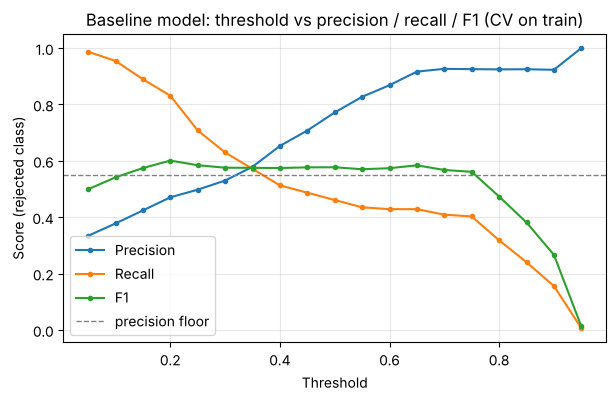

In [11]:
ts = np.arange(0.05, 0.96, 0.05)
pr = [scores(proba_base, t) for t in ts]
plt.figure(figsize=(7, 4))
plt.plot(ts, [s["Precision"] for s in pr], label="Precision", marker="o", ms=3)
plt.plot(ts, [s["Recall"] for s in pr], label="Recall", marker="o", ms=3)
plt.plot(ts, [s["F1"] for s in pr], label="F1", marker="o", ms=3)
plt.axhline(PREC_FLOOR, color="grey", ls="--", lw=1, label="precision floor")
plt.xlabel("Threshold"); plt.ylabel("Score (rejected class)")
plt.title("Baseline model: threshold vs precision / recall / F1 (CV on train)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

### 5c. Change 3: resampling (oversampling the rejected class, training folds only)
Rejected rows are duplicated inside each training fold until both classes are equal. The validation part of each fold is never resampled.

In [12]:
proba_os = cv_proba(X_train, y_train, use_oversample=True)
table({"Baseline": scores(proba_base), "Oversampling (in-fold)": scores(proba_os)})

,Accuracy,Precision,Recall,F1,Missed (FN),False alarms (FP)
Baseline,0.788,0.772,0.461,0.577,83.0,21.0
Oversampling (in-fold),0.772,0.702,0.474,0.566,81.0,31.0


### 5d. Change 4: new features
Four features built from existing columns: `TotalIncome`, `LoanToIncome` (loan size compared with income), `EMI` (loan amount per month of the term) and `IncomeAfterEMI`. Everything else stays the same as the baseline.

In [13]:
X_train_fe = add_features(X_train)
proba_fe = cv_proba(X_train_fe, y_train)
table({"Baseline": scores(proba_base), "New features": scores(proba_fe)})

,Accuracy,Precision,Recall,F1,Missed (FN),False alarms (FP)
Baseline,0.788,0.772,0.461,0.577,83.0,21.0
New features,0.804,0.769,0.539,0.634,71.0,25.0


### 5e. Change 5: limit how deep the trees can memorise (`min_samples_leaf=5`)
A default forest grows trees until they fit the training rows almost perfectly, which is a risk on a small dataset. Here each leaf must contain at least 5 rows. Only this changes compared with the baseline.

In [14]:
proba_leaf = cv_proba(X_train, y_train, min_samples_leaf=5)
table({"Baseline": scores(proba_base), "min_samples_leaf=5": scores(proba_leaf)})

,Accuracy,Precision,Recall,F1,Missed (FN),False alarms (FP)
Baseline,0.788,0.772,0.461,0.577,83.0,21.0
min_samples_leaf=5,0.809,0.929,0.422,0.580,89.0,5.0


### 5f. Putting the useful pieces together
After testing each change alone, I try a few combinations, each at several thresholds. I pick the final setup **by a rule written before looking at the table**: highest recall with precision at least 0.55 (ties go to the higher F1). Still only training data is used.

In [15]:
configs = {
    "Baseline":                       dict(fe=False, cw=None,       os=False),
    "min_samples_leaf=5 only":        dict(fe=False, cw=None,       os=False, extra=dict(min_samples_leaf=5)),
    "Features":                       dict(fe=True,  cw=None,       os=False),
    "Features + balanced":            dict(fe=True,  cw="balanced", os=False),
    "Features + oversampling":        dict(fe=True,  cw=None,       os=True),
    "Features + min_samples_leaf=5":  dict(fe=True,  cw=None,       os=False, extra=dict(min_samples_leaf=5)),
}
thresholds = [0.5, 0.45, 0.4, 0.35, 0.3, 0.25, 0.2]
probas, results = {}, []
for name, c in configs.items():
    Xc = X_train_fe if c["fe"] else X_train
    probas[name] = cv_proba(Xc, y_train, class_weight=c["cw"], use_oversample=c["os"], **c.get("extra", {}))
    for t in thresholds:
        s = scores(probas[name], t)
        results.append({"Setup": name, "Threshold": t, **s})
res = pd.DataFrame(results)

best_per_setup = []
for name in configs:
    r = res[(res.Setup == name) & (res.Precision >= PREC_FLOOR)]
    if len(r):
        best_per_setup.append(r.sort_values(["Recall", "F1"], ascending=False).iloc[0])
summary = pd.DataFrame(best_per_setup).set_index("Setup").round(3)
print(f"Best threshold per setup (highest recall with precision >= {PREC_FLOOR}):")
summary

Best threshold per setup (highest recall with precision >= 0.55):


,Threshold,Accuracy,Precision,Recall,F1,Missed (FN),False alarms (FP)
Setup,,,,,,,
Baseline,0.35,0.735,0.579,0.571,0.575,66,64
min_samples_leaf=5 only,0.35,0.752,0.623,0.526,0.570,73,49
Features,0.35,0.739,0.586,0.578,0.582,65,63
Features + balanced,0.45,0.743,0.595,0.571,0.583,66,60
Features + oversampling,0.40,0.768,0.645,0.578,0.610,65,49
Features + min_samples_leaf=5,0.30,0.727,0.557,0.636,0.594,56,78


In [16]:
eligible = res[res.Precision >= PREC_FLOOR].sort_values(["Recall", "F1"], ascending=False)
best = eligible.iloc[0]
FINAL = dict(setup=best["Setup"], threshold=float(best["Threshold"]))
print("Chosen on training CV:", FINAL)
print(best[["Accuracy", "Precision", "Recall", "F1", "Missed (FN)", "False alarms (FP)"]].round(3).to_dict())

print("\nFull grid for the baseline and the chosen setup:")
res[res.Setup.isin(["Baseline", FINAL["setup"]])].set_index(["Setup", "Threshold"]).round(3)

Chosen on training CV: {'setup': 'Features + min_samples_leaf=5', 'threshold': 0.3}
{'Accuracy': 0.727, 'Precision': 0.557, 'Recall': 0.636, 'F1': 0.594, 'Missed (FN)': 56, 'False alarms (FP)': 78}

Full grid for the baseline and the chosen setup:


Accuracy  Precision  Recall     F1  Missed (FN)  False alarms (FP)
Setup                         Threshold                                                                    
Baseline                      0.50          0.788      0.772   0.461  0.577           83                 21
                              0.45          0.776      0.708   0.487  0.577           79                 31
                              0.40          0.762      0.653   0.513  0.575           75                 42
                              0.35          0.735      0.579   0.571  0.575           66                 64
                              0.30          0.709      0.530   0.630  0.576           57                 86
                              0.25          0.684      0.498   0.708  0.584           45                110
                              0.20          0.654      0.471   0.831  0.601           26                144
Features + min_samples_leaf=5 0.50          0.811      0.851   0.481  0.614           80                 13
                              0.45          0.815      0.825   0.519  0.637           74                 17
                              0.40          0.790      0.726   0.532  0.614           72                 31
                              0.35          0.768      0.649   0.565  0.604           67                 47
                              0.30          0.727      0.557   0.636  0.594           56                 78
                              0.25          0.668      0.481   0.727  0.579           42                121
                              0.20          0.601      0.430   0.838  0.568           25                171

**What I see (training data, repeated 5-fold CV):**

| Change | Precision | Recall | F1 | What happened |
|---|---|---|---|---|
| Baseline (thr 0.5) | 0.772 | 0.461 | 0.577 | reference |
| class_weight balanced | 0.650 | 0.519 | 0.578 | recall up, precision down, F1 same |
| Threshold 0.3 | 0.530 | 0.630 | 0.576 | recall up, precision down, F1 same |
| Threshold 0.2 | 0.471 | 0.831 | 0.601 | many more false alarms (144) |
| Oversampling (in-fold) | 0.702 | 0.474 | 0.566 | no real gain |
| New features | 0.769 | 0.539 | 0.634 | the only change that raised recall **and** F1 without hurting precision |
| min_samples_leaf=5 | 0.929 | 0.422 | 0.580 | very cautious: few false alarms but more misses |

**What I learned:**
- `class_weight` and a lower threshold do the same thing: they move along one trade-off curve (more rejections caught, more false alarms). F1 hardly changes, so they do not make the model smarter.
- Oversampling did not help. Duplicating the same 154 rows gives the forest nothing new to learn.
- The new features helped most, because they describe the loan size *relative to* income, which is what the error analysis pointed to.
- The combination rule (highest recall with precision >= 0.55) picked **Features + min_samples_leaf=5 at threshold 0.3**: precision 0.557, recall 0.636, F1 0.594, only 56 missed (baseline: 83).

**Warning to myself:** differences of 0.02 to 0.03 are small with only 154 rejected rows, so they can be noise. The chosen point also sits just above the precision floor (0.557 vs 0.55), which makes it fragile.

## Step 6: Feature importance

Importances come from the chosen setup trained on the full training set (test set still locked).

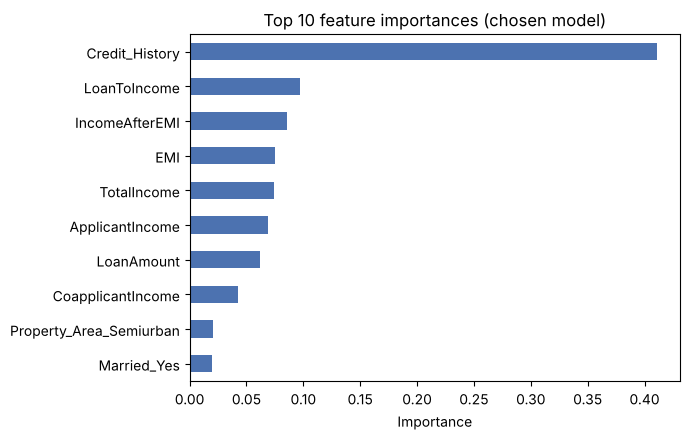

Credit_History             0.411
LoanToIncome               0.097
IncomeAfterEMI             0.086
EMI                        0.075
TotalIncome                0.075
ApplicantIncome            0.069
LoanAmount                 0.062
CoapplicantIncome          0.043
Property_Area_Semiurban    0.021
Married_Yes                0.020
Dependents                 0.014
Property_Area_Urban        0.008
Education_Not Graduate     0.008
Loan_Amount_Term           0.006
Self_Employed_Yes          0.004
Gender_Male                0.003


In [17]:
cfg = configs[FINAL["setup"]]
Xf = X_train_fe if cfg["fe"] else X_train
Xf_fit, yf_fit = (oversample(Xf, y_train) if cfg["os"] else (Xf, y_train))
final_rf = RandomForestClassifier(random_state=RANDOM_STATE, class_weight=cfg["cw"], **cfg.get("extra", {}))
final_rf.fit(Xf_fit, yf_fit)

imp = pd.Series(final_rf.feature_importances_, index=Xf.columns).sort_values(ascending=False)
ax = imp.head(10).sort_values().plot(kind="barh", color="#4C72B0", figsize=(7, 4.5))
ax.set_title("Top 10 feature importances (chosen model)")
ax.set_xlabel("Importance")
plt.tight_layout(); plt.show()
print(imp.round(3).to_string())

In [18]:
# is Credit_History suspiciously dominant? quick check of how well it alone separates the classes
print("Rejected share by Credit_History (training data, missing filled with 1):")
print(pd.crosstab(X_train["Credit_History"], y_train, normalize="index").round(2).rename(columns={0: "Approved", 1: "Rejected"}))
print("\nRaw data (before filling), rejected share when Credit_History is missing: {:.0%}".format(y_train[ch_missing_train].mean()))

Rejected share by Credit_History (training data, missing filled with 1):
Loan_Status     Approved  Rejected
Credit_History                    
0.0                 0.07      0.93
1.0                 0.79      0.21

Raw data (before filling), rejected share when Credit_History is missing: 26%


### Removing the least important features
I drop the weakest 3 and then the weakest 5 features (by the importance ranking above) and compare with the full feature set, same CV, same threshold.

In [19]:
weak_order = imp.sort_values().index.tolist()
t = FINAL["threshold"]
rows = {"All features": scores(probas[FINAL["setup"]], t)}
drop_probas = {}
for k in [3, 5]:
    drop = weak_order[:k]
    Xd = Xf.drop(columns=drop)
    drop_probas[k] = cv_proba(Xd, y_train, class_weight=cfg["cw"], use_oversample=cfg["os"], **cfg.get("extra", {}))
    rows[f"Drop weakest {k}"] = scores(drop_probas[k], t)
    print(f"Dropped weakest {k}:", drop)
table(rows)

Dropped weakest 3: ['Gender_Male', 'Self_Employed_Yes', 'Loan_Amount_Term']


Dropped weakest 5: ['Gender_Male', 'Self_Employed_Yes', 'Loan_Amount_Term', 'Education_Not Graduate', 'Property_Area_Urban']


,Accuracy,Precision,Recall,F1,Missed (FN),False alarms (FP)
All features,0.727,0.557,0.636,0.594,56.0,78.0
Drop weakest 3,0.729,0.557,0.662,0.605,52.0,81.0
Drop weakest 5,0.715,0.539,0.630,0.581,57.0,83.0


In [20]:
# rule: keep a smaller feature set only if F1 rises by >= 0.01 and recall does not fall
full = rows["All features"]
DROP_K = 0
for k in [3, 5]:
    r = rows[f"Drop weakest {k}"]
    if r["F1"] >= full["F1"] + 0.01 and r["Recall"] >= full["Recall"]:
        DROP_K = k
DROP_COLS = weak_order[:DROP_K] if DROP_K else []
print("Features dropped in the final model:", DROP_COLS if DROP_COLS else "none (removing features did not help)")

Features dropped in the final model: ['Gender_Male', 'Self_Employed_Yes', 'Loan_Amount_Term']


**Top 3 features in simple words:**
1. **Credit_History (0.41)**: whether the applicant paid earlier debts properly. It dominates: 93% of applicants with a bad history were rejected, against 21% with a good history.
2. **LoanToIncome (0.10)**: how big the loan is compared with the family's income. A big loan on a small income is riskier.
3. **IncomeAfterEMI (0.09)**: how much income is left after the monthly loan payment.

**Leakage check:** I do not see leakage. `Credit_History` is high, but it is information that exists before the decision and it is the strongest real signal. My new features are built only from the input columns, never from `Loan_Status`. What I cannot verify from the file is *when* `Credit_History` was recorded. If the bank wrote it after deciding, it would be leakage, so this is worth asking about in a real project.

**Removing weak features:** dropping the 3 weakest (`Gender_Male`, `Self_Employed_Yes`, `Loan_Amount_Term`) gave recall 0.636 to 0.662 and F1 0.594 to 0.605 with the same precision, so my rule kept that smaller set. Dropping 5 made things slightly worse, so I stopped at 3. The gain is small and may be noise, but removing gender is also a good thing for a lending model.

## Step 7: Final test and comparison

This is the first and only time the test set is evaluated. The three versions are trained on the full training set:
1. **Dummy** (always "approved")
2. **Baseline** RandomForest (default, threshold 0.5)
3. **Final** model chosen in Steps 5 and 6

In [21]:
def fit_version(Xtr_, ytr_, Xte_, cw=None, os_=False, **params):
    if os_:
        Xtr_, ytr_ = oversample(Xtr_, ytr_)
    m = RandomForestClassifier(random_state=RANDOM_STATE, class_weight=cw, **params).fit(Xtr_, ytr_)
    return m.predict_proba(Xte_)[:, 1]

# 1) dummy
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pred_dummy = dummy.predict(X_test)

# 2) baseline
pred_base = (fit_version(X_train, y_train, X_test) >= 0.5).astype(int)

# 3) final
X_test_fe = add_features(X_test)
Xtr_final = (X_train_fe if cfg["fe"] else X_train).drop(columns=DROP_COLS)
Xte_final = (X_test_fe if cfg["fe"] else X_test).drop(columns=DROP_COLS)
proba_final = fit_version(Xtr_final, y_train, Xte_final, cw=cfg["cw"], os_=cfg["os"], **cfg.get("extra", {}))
pred_final = (proba_final >= FINAL["threshold"]).astype(int)

def row(pred):
    return {"Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred, zero_division=0)}

final_table = pd.DataFrame({
    "Dummy (most_frequent)": row(pred_dummy),
    "Baseline RandomForest": row(pred_base),
    f"Final ({FINAL['setup']}, thr {FINAL['threshold']})": row(pred_final),
}).T.round(3)
final_table.index.name = "Version"
final_table

,Accuracy,Precision,Recall,F1
Version,,,,
Dummy (most_frequent),0.691,0.000,0.000,0.000
Baseline RandomForest,0.780,0.690,0.526,0.597
"Final (Features + min_samples_leaf=5, thr 0.3)",0.683,0.488,0.553,0.519


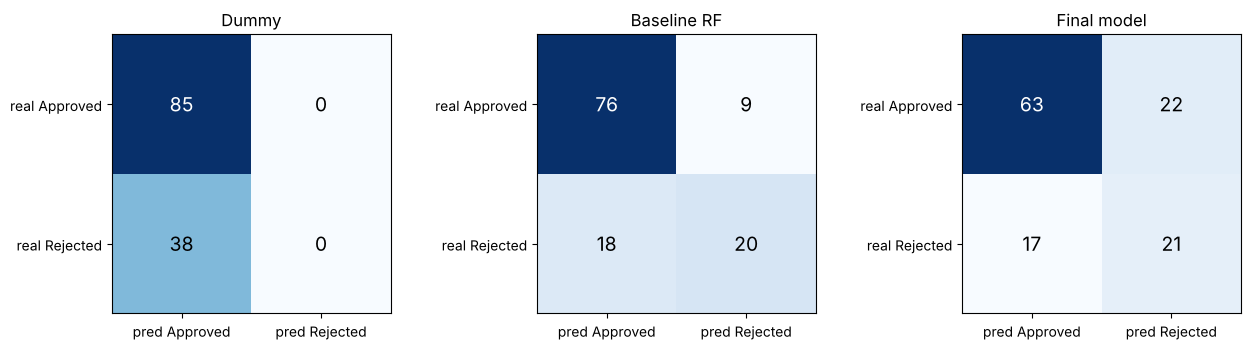

Baseline RF: caught 20 of 38 rejected loans, missed 18, false alarms 9 (out of 85 approved)
Final model: caught 21 of 38 rejected loans, missed 17, false alarms 22 (out of 85 approved)


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (name, pred) in zip(axes, [("Dummy", pred_dummy), ("Baseline RF", pred_base), ("Final model", pred_final)]):
    cm = confusion_matrix(y_test, pred)
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["pred Approved", "pred Rejected"]); ax.set_yticklabels(["real Approved", "real Rejected"])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_title(name)
plt.tight_layout(); plt.show()

for name, pred in [("Baseline RF", pred_base), ("Final model", pred_final)]:
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"{name}: caught {tp} of {tp + fn} rejected loans, missed {fn}, false alarms {fp} (out of {tn + fp} approved)")

## What the test set says

| Version | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
| Dummy | 0.691 | 0.000 | 0.000 | 0.000 |
| Baseline RandomForest | 0.780 | 0.690 | 0.526 | 0.597 |
| Final model | 0.683 | 0.488 | 0.553 | 0.519 |

**The honest result: my improvement did not carry over to the test set.**
- The final model caught 21 of 38 rejected loans, the baseline caught 20. That is **one extra case** (recall +2.7 points).
- To get that one case, false alarms went from 9 to 22 (+13), precision fell from 0.69 to 0.49 and F1 fell from 0.597 to 0.519.

**Why I think this happened:** (1) the test set has only 38 rejected loans, so one case moves recall by 2.6 points and the result is noisy; (2) the gains I saw in cross-validation were small (0.02 to 0.03) and probably partly noise; (3) the rule I set (highest recall with precision above 0.55) picked a threshold of 0.3 that sits right at the edge of the floor, so it is not a stable choice. I did not change the setup after seeing the test result, because that would mean tuning on the test set.

**Decision:** in real life I would **not** use my final model. The baseline catches almost the same number of rejected loans with far fewer false alarms. A lower threshold only makes sense if one missed bad loan costs the bank much more than about 13 extra manual checks per extra catch, which is a bad price here.

**Trade-off:** more recall always costs more false alarms (good customers being checked or turned away).

**Bigger lesson:** the biggest limit is the data, not the model settings. Credit history explains most of the decisions, and the remaining rejected loans look like approved ones. More data or more informative columns would help more than more tuning. A next step I would try is the new features at the normal 0.5 threshold with more data, but I have not tested that on the test set.

---
*Reproduce:* put `loan_prediction.csv` next to this notebook, install `requirements.txt`, then **Kernel > Restart and Run All**. Everything uses `random_state=42`.